# In-Depth Analysis of Delhi's Air Quality Index (AQI)
**ShadowFox Data Science Internship — Intermediate Task**

This notebook analyzes hourly air-quality data for Delhi to understand pollutant behavior, daily pollution cycles, and overall AQI severity, using a CPCB-style (Central Pollution Control Board) AQI approach.

## 1. Dataset and Scope

The dataset contains hourly air-quality measurements for Delhi from **1 January 2023 to 24 January 2023** (561 hourly records), covering eight pollutants: CO, NO, NO2, O3, SO2, PM2.5, PM10, and NH3. No latitude/longitude or station identifiers are included, so this represents a **single monitoring point**, not multiple locations across the city.

Because the record spans only 24 days within one calendar month (January), this analysis focuses on **daily and hour-of-day (diurnal) patterns and pollutant relationships**, rather than year-round seasonal comparison or city-wide geographic comparison, which this data cannot support. Sections 6.6 and 6.7 address these two points directly instead of skipping them, since the task brief asks for them explicitly.

## 2. Research Questions

1. What are the dominant pollutants driving poor air quality in this period, and how do they relate to one another?
2. Is there a repeating within-day (diurnal) pattern to pollution levels, and does it line up with traffic/activity hours?
3. How severe is air quality against Indian CPCB AQI categories, and how much does it vary day to day?
4. What can and cannot be said about seasonal and geographical variation given this dataset?

## 3. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("delhi_aqi.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
df["hour"] = df["date"].dt.hour
df["day"] = df["date"].dt.date

print("Shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
df.head()

Shape: (561, 11)
Date range: 2023-01-01 00:00:00 to 2023-01-24 08:00:00


,date,co,no,no2,o3,so2,pm2_5,pm10,nh3,hour,day
0,2023-01-01 00:00:00,1655.58,1.66,39.41,5.90,17.88,169.29,194.64,5.83,0,2023-01-01
1,2023-01-01 01:00:00,1869.20,6.82,42.16,1.99,22.17,182.84,211.08,7.66,1,2023-01-01
2,2023-01-01 02:00:00,2510.07,27.72,43.87,0.02,30.04,220.25,260.68,11.40,2,2023-01-01
3,2023-01-01 03:00:00,3150.94,55.43,44.55,0.85,35.76,252.90,304.12,13.55,3,2023-01-01
4,2023-01-01 04:00:00,3471.37,68.84,45.24,5.45,39.10,266.36,322.80,14.19,4,2023-01-01


In [2]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,561,2023-01-12 16:00:00,2023-01-01 00:00:00,2023-01-06 20:00:00,2023-01-12 16:00:00,2023-01-18 12:00:00,2023-01-24 08:00:00,NaN
co,561.0,3814.94221,654.22,1708.98,2590.18,4432.68,16876.22,3227.744681
no,561.0,51.181979,0.0,3.38,13.3,59.01,425.58,83.904476
no2,561.0,75.292496,13.37,44.55,63.75,97.33,263.21,42.473791
o3,561.0,30.141943,0.0,0.07,11.8,47.21,164.51,39.979405
so2,561.0,64.655936,5.25,28.13,47.21,77.25,511.17,61.07308
pm2_5,561.0,358.256364,60.1,204.45,301.17,416.65,1310.2,227.359117
pm10,561.0,420.988414,69.08,240.9,340.9,482.57,1499.27,271.287026
nh3,561.0,26.425062,0.63,8.23,14.82,26.35,267.51,36.563094
hour,561.0,11.379679,0.0,5.0,11.0,17.0,23.0,6.944696


In [3]:
df.isna().sum()

date     0
co       0
no       0
no2      0
o3       0
so2      0
pm2_5    0
pm10     0
nh3      0
hour     0
day      0
dtype: int64

No missing values in any pollutant column at the raw-data level. The checks below go a step further and validate the **timestamps themselves**, since gaps or duplicate timestamps would silently distort any rolling-average or time-based calculation later in the notebook.

## 4. Data Quality Checks

Before computing any time-based statistics (like a 24-hour rolling AQI), it's important to confirm the hourly timestamp series is complete and free of duplicates. These checks are calculated directly from the data — nothing here is assumed in advance.

In [4]:
# Duplicate timestamp check
duplicate_count = df["date"].duplicated().sum()
print("Duplicate timestamps:", duplicate_count)

# Missing hourly timestamp check
expected_range = pd.date_range(start=df["date"].min(), end=df["date"].max(), freq="h")
missing_timestamps = expected_range.difference(df["date"])

print("Expected hourly timestamps in range:", len(expected_range))
print("Actual timestamps present:", df["date"].nunique())
print("Missing timestamps:", len(missing_timestamps))

if len(missing_timestamps) > 0:
    print("\nFirst few missing timestamps:")
    print(missing_timestamps[:10])
else:
    print("\nNo missing hourly timestamps — the series is fully continuous.")

Duplicate timestamps: 0
Expected hourly timestamps in range: 561
Actual timestamps present: 561
Missing timestamps: 0

No missing hourly timestamps — the series is fully continuous.


**Result:** the dataset has **0 duplicate timestamps** and **0 missing hourly timestamps** — every hour from 1 Jan 2023 00:00 to 24 Jan 2023 08:00 is present exactly once. This means downstream rolling-window calculations can safely assume one row per hour with no gaps to bridge.

## 5. Computing AQI (CPCB-Style, PM-Based)

India's CPCB AQI framework computes a sub-index per pollutant using piecewise-linear breakpoints, and the overall AQI is the **maximum sub-index** across pollutants ("worst pollutant" approach), evaluated over a **true 24-hour rolling average**.

**Scope of this implementation:** sub-indices are computed here for **PM2.5 and PM10 only**. The other six pollutants (CO, NO, NO2, O3, SO2, NH3) each have their own CPCB sub-index formulas, which are not implemented in this notebook. This is a deliberate simplification, not a full multi-pollutant CPCB AQI — it is a reasonable one for this dataset because PM2.5 and PM10 are the pollutants most associated with visible haze and health risk in Delhi winters, and the correlation analysis in Section 6.4 shows PM2.5 tracking most other pollutants closely enough that it captures the overall pollution level well. The AQI figures below should be read as **PM-derived AQI**, not the complete official CPCB index.

**On the 24-hour rolling window:** CPCB's AQI is explicitly a 24-hour average, so a value only qualifies as a genuine 24-hour AQI reading once 24 full hourly observations are available. The rolling average is therefore computed with `min_periods=24` (using a time-based `"24h"` window, which stays correct even if the data ever had gaps — see Section 4). This means the **first 23 hours of the dataset (1 Jan, 00:00–22:00) do not get a valid AQI value**, since a full trailing 24-hour window doesn't exist yet at that point. Those hours are excluded from AQI averages rather than filled in with a partial estimate.

In [5]:
def pm25_subindex(x):
    if x <= 30: return x * 50 / 30
    elif x <= 60: return 50 + (x - 30) * 50 / 30
    elif x <= 90: return 100 + (x - 60) * 100 / 30
    elif x <= 120: return 200 + (x - 90) * 100 / 30
    elif x <= 250: return 300 + (x - 120) * 100 / 130
    else: return 400 + (x - 250) * 100 / 130

def pm10_subindex(x):
    if x <= 50: return x
    elif x <= 100: return x
    elif x <= 250: return 100 + (x - 100) * 100 / 150
    elif x <= 350: return 200 + (x - 250)
    elif x <= 430: return 300 + (x - 350) * 100 / 80
    else: return 400 + (x - 430) * 100 / 80

# Time-based 24h rolling average, requiring a full 24 hourly observations (min_periods=24)
df = df.set_index("date")
df["pm25_24h"] = df["pm2_5"].rolling("24h", min_periods=24).mean()
df["pm10_24h"] = df["pm10"].rolling("24h", min_periods=24).mean()
df = df.reset_index()

print("Rows without a valid 24h rolling average (insufficient history):", df["pm25_24h"].isna().sum())

df["pm25_subindex"] = df["pm25_24h"].apply(lambda x: pm25_subindex(x) if pd.notna(x) else np.nan)
df["pm10_subindex"] = df["pm10_24h"].apply(lambda x: pm10_subindex(x) if pd.notna(x) else np.nan)
df["AQI"] = df[["pm25_subindex", "pm10_subindex"]].max(axis=1)

def category(aqi):
    if pd.isna(aqi):
        return np.nan
    if aqi <= 50: return "Good"
    elif aqi <= 100: return "Satisfactory"
    elif aqi <= 200: return "Moderate"
    elif aqi <= 300: return "Poor"
    elif aqi <= 400: return "Very Poor"
    else: return "Severe"

df["AQI_category"] = df["AQI"].apply(category)

# All AQI-based analysis below uses only rows with a valid (complete) 24h average
aqi_valid = df.dropna(subset=["AQI"]).copy()
print("Hours with a valid AQI value:", len(aqi_valid), "of", len(df), "total hours")
print("Mean AQI:", round(aqi_valid["AQI"].mean(), 1))

df[["date", "pm2_5", "pm25_24h", "pm10", "pm10_24h", "AQI", "AQI_category"]].head(26)

Rows without a valid 24h rolling average (insufficient history): 23
Hours with a valid AQI value: 538 of 561 total hours
Mean AQI: 495.4


,date,pm2_5,pm25_24h,pm10,pm10_24h,AQI,AQI_category
0,2023-01-01 00:00:00,169.29,NaN,194.64,NaN,NaN,NaN
1,2023-01-01 01:00:00,182.84,NaN,211.08,NaN,NaN,NaN
2,2023-01-01 02:00:00,220.25,NaN,260.68,NaN,NaN,NaN
3,2023-01-01 03:00:00,252.90,NaN,304.12,NaN,NaN,NaN
4,2023-01-01 04:00:00,266.36,NaN,322.80,NaN,NaN,NaN
5,2023-01-01 05:00:00,276.54,NaN,336.79,NaN,NaN,NaN
6,2023-01-01 06:00:00,295.40,NaN,357.07,NaN,NaN,NaN
7,2023-01-01 07:00:00,158.83,NaN,182.61,NaN,NaN,NaN
8,2023-01-01 08:00:00,134.39,NaN,153.47,NaN,NaN,NaN
9,2023-01-01 09:00:00,133.22,NaN,152.09,NaN,NaN,NaN


As expected, the first 23 rows show `NaN` for the rolling averages and AQI — these hours are excluded from every AQI statistic from this point forward. All AQI-based figures below (mean AQI, category shares, daily AQI) are computed only over `aqi_valid`, the subset with a complete 24-hour window.

## 6. Findings

### 6.1 Overall Air Quality Is Severe

AQI_category
Severe       74.7
Very Poor    25.3
Name: proportion, dtype: float64


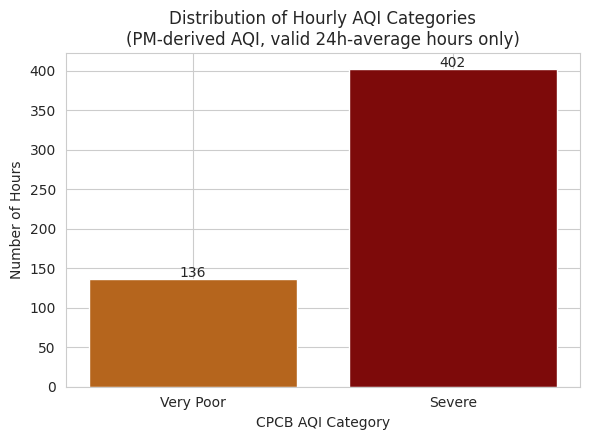

In [6]:
cat_dist = (aqi_valid["AQI_category"].value_counts(normalize=True) * 100).round(1)
print(cat_dist)

order = ["Very Poor", "Severe"]
counts = aqi_valid["AQI_category"].value_counts().reindex(order)
colors_map = {"Very Poor": "#b5651d", "Severe": "#7d0a0a"}

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(counts.index, counts.values, color=[colors_map[c] for c in counts.index])
ax.set_ylabel("Number of Hours")
ax.set_xlabel("CPCB AQI Category")
ax.set_title("Distribution of Hourly AQI Categories\n(PM-derived AQI, valid 24h-average hours only)")
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha="center")
plt.tight_layout()
plt.show()

Across the 538 hours with a valid 24-hour AQI reading, the mean AQI was **~495**, which falls in CPCB's **"Severe"** category (AQI > 400). About **75% of valid hours were Severe** and the remaining **25% Very Poor** — no hour in the dataset reached Moderate, Poor, Satisfactory, or Good.

### 6.2 PM2.5 and PM10 Are Consistently Far Above Safe Limits

Mean PM2.5: 358.3 µg/m³  (India 24h standard: 60 µg/m³)
Mean PM10: 421.0 µg/m³


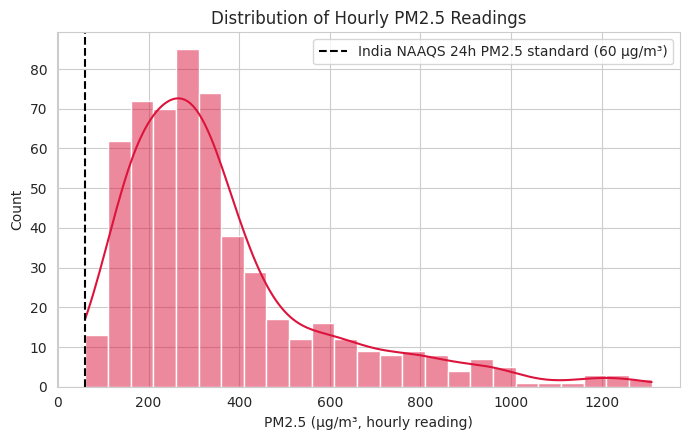

In [7]:
print("Mean PM2.5:", round(df["pm2_5"].mean(), 1), "µg/m³  (India 24h standard: 60 µg/m³)")
print("Mean PM10:", round(df["pm10"].mean(), 1), "µg/m³")

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(df["pm2_5"], bins=25, kde=True, color="crimson", ax=ax)
ax.axvline(60, color="black", linestyle="--", label="India NAAQS 24h PM2.5 standard (60 µg/m³)")
ax.set_xlabel("PM2.5 (µg/m³, hourly reading)")
ax.set_ylabel("Count")
ax.set_title("Distribution of Hourly PM2.5 Readings")
ax.legend()
plt.tight_layout()
plt.show()

The mean hourly PM2.5 was **358 µg/m³**, roughly **six times** India's 24-hour PM2.5 standard of 60 µg/m³, and well above the WHO guideline of 15 µg/m³. Mean PM10 was **421 µg/m³**. This is the raw hourly PM2.5/PM10 series (not the rolling AQI average), so it reflects instantaneous pollutant levels rather than the smoothed AQI figure above.

### 6.3 A Clear Diurnal (Daily Cycle) Pattern Exists

Lowest PM2.5 hour: 8 -> 194.3 µg/m³
Peak PM2.5 hour: 17 -> 539.5 µg/m³


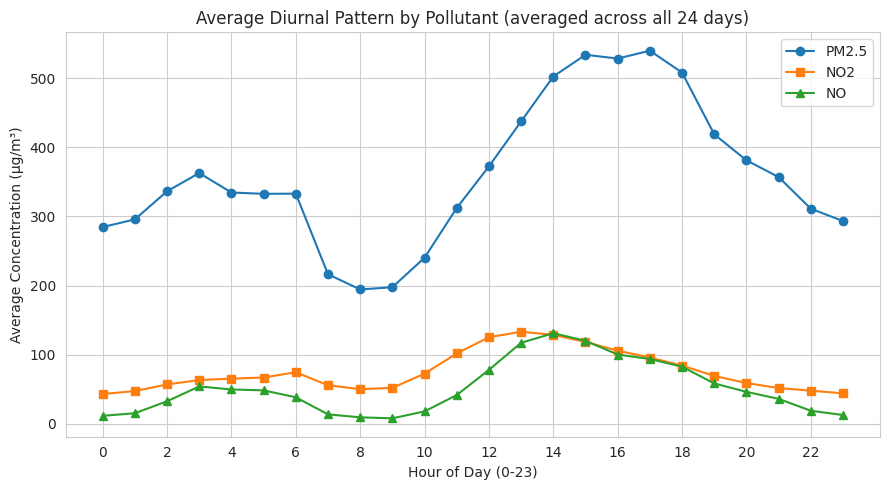

In [8]:
hourly = df.groupby("hour")[["pm2_5", "no2", "no"]].mean()
print("Lowest PM2.5 hour:", hourly["pm2_5"].idxmin(), "->", round(hourly["pm2_5"].min(), 1), "µg/m³")
print("Peak PM2.5 hour:", hourly["pm2_5"].idxmax(), "->", round(hourly["pm2_5"].max(), 1), "µg/m³")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(hourly.index, hourly["pm2_5"], marker="o", label="PM2.5")
ax.plot(hourly.index, hourly["no2"], marker="s", label="NO2")
ax.plot(hourly.index, hourly["no"], marker="^", label="NO")
ax.set_xlabel("Hour of Day (0-23)")
ax.set_ylabel("Average Concentration (µg/m³)")
ax.set_title("Average Diurnal Pattern by Pollutant (averaged across all 24 days)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()

Concentrations dip in the mid-morning (lowest around **8 AM**, ~194 µg/m³) and climb through the afternoon to a sharp peak in the early evening (highest around **5 PM**, ~540 µg/m³ — roughly 2.8x the morning low). This matches the well-documented winter pattern in Delhi, where the atmospheric boundary layer rises with the sun (dispersing pollutants) and collapses after sunset (trapping them near the ground).

period
Evening rush (17-21)    440.8
Morning rush (7-10)     211.9
Off-peak                370.4
Name: pm2_5, dtype: float64


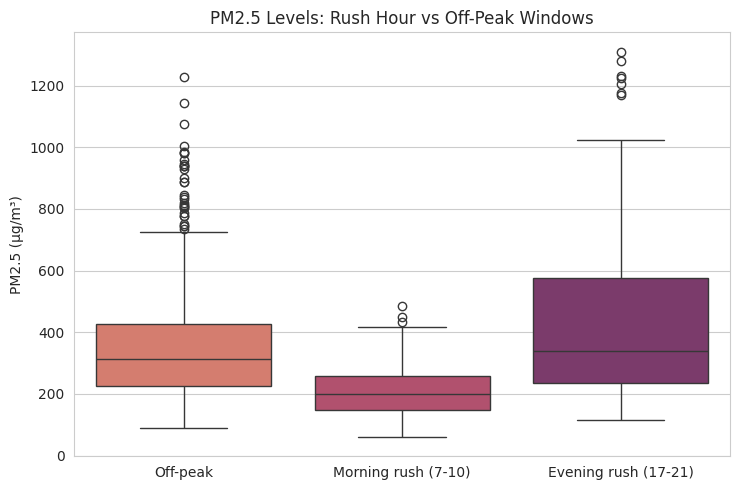

In [9]:
df["period"] = df["hour"].apply(lambda h: "Morning rush (7-10)" if 7 <= h <= 10
                                 else ("Evening rush (17-21)" if 17 <= h <= 21 else "Off-peak"))
print(df.groupby("period")["pm2_5"].mean().round(1))

fig, ax = plt.subplots(figsize=(7.5, 5))
sns.boxplot(data=df, x="period", y="pm2_5",
            order=["Off-peak", "Morning rush (7-10)", "Evening rush (17-21)"],
            hue="period", legend=False, palette="flare", ax=ax)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_xlabel("")
ax.set_title("PM2.5 Levels: Rush Hour vs Off-Peak Windows")
plt.tight_layout()
plt.show()

Off-peak hours (which include the pollution-prone late night/early morning window) averaged **higher** PM2.5 (370 µg/m³) than the defined morning rush window (212 µg/m³), while the evening rush window was highest of all (441 µg/m³). This suggests **atmospheric conditions** (temperature inversion, low wind) are at least as influential as traffic timing alone in shaping the daily pollution cycle.

### 6.4 Pollutant Correlations Point to Shared Combustion Sources

pm2_5    1.00
pm10     0.99
co       0.95
no       0.89
nh3      0.72
no2      0.70
so2      0.65
o3      -0.45
Name: pm2_5, dtype: float64


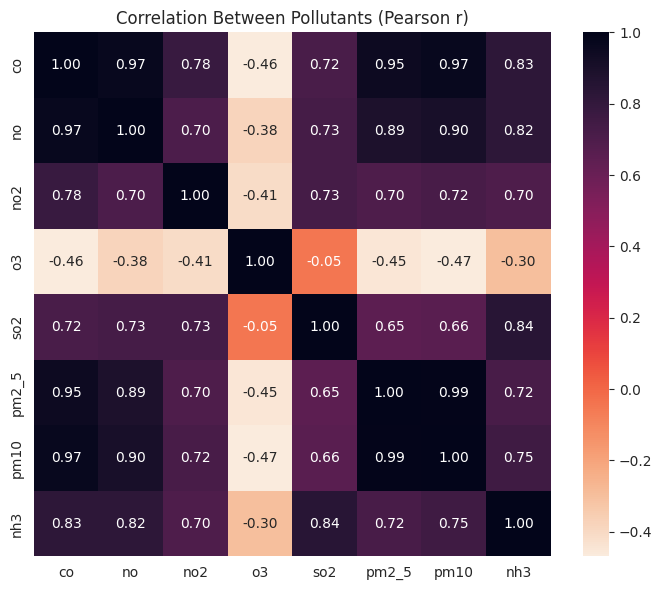

In [10]:
pollutants = ["co", "no", "no2", "o3", "so2", "pm2_5", "pm10", "nh3"]
corr = df[pollutants].corr()
print(corr["pm2_5"].sort_values(ascending=False).round(2))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="rocket_r", ax=ax)
ax.set_title("Correlation Between Pollutants (Pearson r)")
plt.tight_layout()
plt.show()

PM2.5 is very strongly correlated with **PM10 (r = 0.99)** and **CO (r = 0.95)**, strongly correlated with **NO (r = 0.89)**, and moderately correlated with **NH3 (r = 0.72)** and **NO2 (r = 0.70)**. It is **negatively correlated with O3 (r = -0.45)** — expected, since ozone is depleted by fresh NO emissions (the titration effect) and forms photochemically, which is suppressed on hazy, low-sunlight winter days.

The tight PM–CO–NO clustering is a signature of **combustion sources** — vehicle exhaust, biomass/crop-residue burning, and solid-fuel heating are all plausible contributors during a Delhi winter. This also supports the simplification in Section 5: since PM2.5 moves closely with most other pollutants, a PM-based AQI captures much of the overall pollution signal even without full sub-indices for every pollutant.

### 6.5 Daily and Full-Period AQI Trend

In [11]:
daily_aqi = aqi_valid.groupby(aqi_valid["date"].dt.date)["AQI"].mean().round(1)
print("Daily mean AQI (valid hours only):")
print(daily_aqi)
print("\nLowest daily average AQI:", daily_aqi.min(), "on", daily_aqi.idxmin())
print("Highest daily average AQI:", daily_aqi.max(), "on", daily_aqi.idxmax())

Daily mean AQI (valid hours only):
date
2023-01-01    549.2
2023-01-02    800.6
2023-01-03    742.5
2023-01-04    426.2
2023-01-05    483.1
2023-01-06    531.7
2023-01-07    476.4
2023-01-08    442.2
2023-01-09    560.8
2023-01-10    588.7
2023-01-11    507.3
2023-01-12    498.3
2023-01-13    498.3
2023-01-14    609.7
2023-01-15    327.5
2023-01-16    328.8
2023-01-17    359.4
2023-01-18    458.1
2023-01-19    523.3
2023-01-20    575.7
2023-01-21    382.2
2023-01-22    369.7
2023-01-23    381.6
2023-01-24    558.4
Name: AQI, dtype: float64

Lowest daily average AQI: 327.5 on 2023-01-15
Highest daily average AQI: 800.6 on 2023-01-02


Daily average AQI ranged from a low of **~328 (15–16 Jan)** to a peak of **~801 (2 Jan)**. Even the calmer days stayed within Very Poor/Severe territory — this reads as a **sustained pollution episode**, not an occasional spike. (Note: 1 Jan's daily average is based on a partial day, since only hour 23 onward has a valid 24h AQI value.)

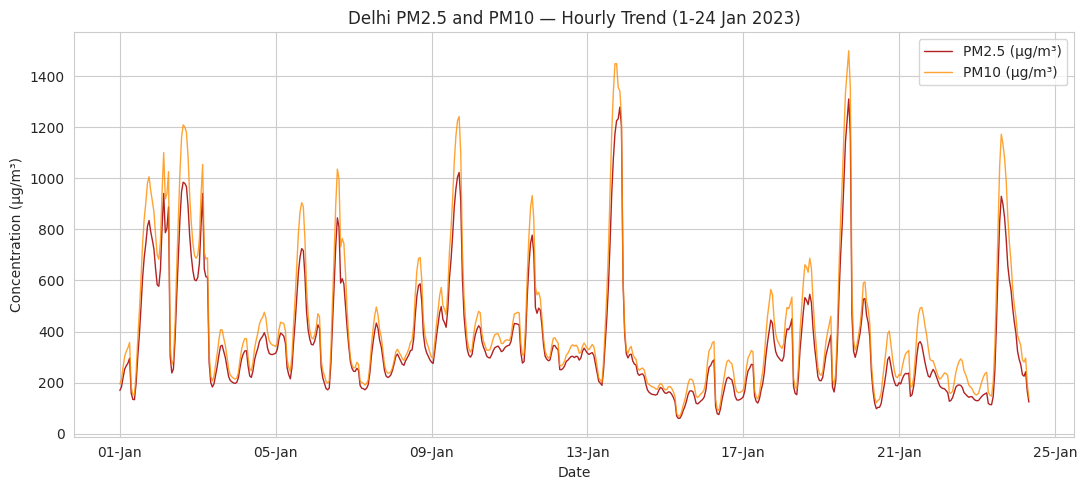

In [12]:
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(df["date"], df["pm2_5"], color="firebrick", label="PM2.5 (µg/m³)", linewidth=1)
ax1.plot(df["date"], df["pm10"], color="darkorange", label="PM10 (µg/m³)", linewidth=1, alpha=0.8)
ax1.set_ylabel("Concentration (µg/m³)")
ax1.set_xlabel("Date")
ax1.set_title("Delhi PM2.5 and PM10 — Hourly Trend (1-24 Jan 2023)")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax1.legend(loc="upper right")
plt.tight_layout()
plt.show()

Plotting PM2.5 and PM10 across all 24 days shows repeated evening peaks nested within a period of generally elevated pollution, without any days approaching safe levels.

### 6.6 Seasonal Analysis — Scope and Limitation

The dataset covers **only January 2023** — a single calendar month, entirely within North India's winter season. Every timestamp in the data falls in the same month, as confirmed below.

In [13]:
months_present = df["date"].dt.to_period("M").unique()
print("Distinct year-month values present in the dataset:", list(months_present))
print("Number of distinct days covered:", df["date"].dt.date.nunique())

Distinct year-month values present in the dataset: [Period('2023-01', 'M')]
Number of distinct days covered: 24


**What this dataset can show:** a detailed hour-by-hour and day-by-day picture of pollution behavior *during one winter period* — which is what Sections 6.1–6.5 do.

**What this dataset cannot show:** any comparison between seasons (winter vs. summer vs. monsoon vs. post-monsoon). A statistically valid seasonal comparison would require pollutant readings spanning at least a full year, ideally with multiple years to average out day-to-day noise. Delhi's air quality is known to vary substantially across seasons due to factors such as crop-residue burning (autumn/early winter), temperature inversions (winter), dust storms (summer), and monsoon washout (monsoon) — but none of these can be tested against this dataset, since there is no non-winter data to compare against.

This notebook therefore does **not** claim a seasonal comparison. The Severe/Very Poor conditions found here should be read as a **winter-period snapshot**, not a year-round characterization of Delhi's air quality.

### 6.7 Geographical Analysis — Scope and Limitation

The dataset contains **no latitude, longitude, or station identifier** — every row is a single time series, implying one monitoring location (or an already-aggregated city-level figure) for the entire period.

**What this means for geographic analysis:**
- Differences between areas of Delhi (e.g., industrial zones vs. residential neighborhoods vs. traffic corridors) **cannot be measured** with this dataset.
- Pollution "hotspots" **cannot be identified** — there is nothing to compare against.
- Any statement about one part of Delhi being more polluted than another would be **speculation, not something this data supports**.

This notebook therefore does not attempt geographic comparisons or hotspot claims.

**Future analysis:** if station-level data were available — for example, readings from Delhi's multiple CPCB/DPCC monitoring stations (Anand Vihar, RK Puram, Punjabi Bagh, etc.) each tagged with a location — the same AQI and correlation methodology used here could be repeated per station, and then compared spatially (e.g., choropleth or scatter map of station-level mean AQI) to identify which parts of the city are consistently worse, and to relate that to land use (traffic density, industrial activity, green cover).

## 7. Discussion: What This Means for Air Quality Strategy

- **Timing of interventions matters.** Since pollution consistently peaks in the early evening and stays high overnight, restrictions timed only to daytime traffic (e.g. odd-even schemes during business hours) will miss the worst window. Evening and overnight measures — restricting open burning, staggering evening traffic, avoiding outdoor exertion after 4–5 PM — would target the actual peak.
- **Combustion is the common thread.** The strong PM–CO–NO correlation points toward vehicular and biomass-burning sources rather than industrial SO2 alone (SO2 correlates more weakly). Curbing crop-residue burning and improving vehicle emission standards would likely address the dominant pollutants together, since they rise and fall in tandem.
- **Weather-aware alerts are needed.** Because off-peak (overnight) hours were sometimes as polluted as rush hour, health advisories should be based on real-time AQI and forecasted inversion conditions, not a fixed "avoid rush hour" rule.
- **Seasonal and geographic claims require more data.** As established in Sections 6.6–6.7, extending this analysis to a full-year, multi-station dataset would be needed before drawing seasonal or location-specific conclusions.

## 8. Limitations

- **Single monitoring location** — no latitude/longitude or station ID; cross-city or geographic comparison is not possible with this data.
- **24-day window within January only** — captures one winter period, not annual seasonality; no summer, monsoon, or multi-year comparison is possible.
- **PM-based AQI, not a full multi-pollutant CPCB AQI** — only PM2.5 and PM10 sub-indices are computed; CO, NO2, SO2, O3, and NH3 have their own CPCB sub-indices that are not implemented here.
- **First 23 hours have no valid AQI value**, since a complete 24-hour rolling window isn't available until then; these hours are excluded from AQI statistics (but retained for pollutant-level analysis in Sections 6.2–6.4).

## 9. Conclusion

Over the observed period (1–24 January 2023), Delhi's air quality was **consistently Severe to Very Poor** by CPCB standards, with a mean PM-derived AQI of ~495 and PM2.5 levels averaging roughly six times the Indian 24-hour safety standard. Pollution followed a repeatable **daily cycle**, dipping in the mid-morning and peaking sharply in the early evening — a pattern consistent with Delhi's known winter temperature-inversion behavior rather than traffic timing alone. PM2.5, PM10, CO, and NO rose and fell together, pointing to **combustion-related sources** (vehicles, biomass burning, solid-fuel heating) as the likely common driver, while ozone moved in the opposite direction as expected.

These findings describe a genuine and serious winter pollution episode, but they are bounded by the dataset: **one location, 24 days, one month**. They should not be read as claims about Delhi's air quality across all seasons or across the whole city — the notebook has been explicit about that boundary rather than extrapolating beyond what the data supports. A fuller picture would require multi-station, multi-season data covering at least a full year.

## 10. Tools Used
Python, pandas (data processing, timestamp validation, rolling-window AQI calculation), NumPy (sub-index formulas), and Matplotlib/Seaborn (all visualizations).